# KYC: umbrales económicos y capacidad de revisión

## Resumen de la ejecución

Datos sintéticos; resultados de esta ejecución:

- **Costo sin capacidad (COP):** 8025285.9
- **Costo con 60 minutos (COP):** 4274124.94
- **Costo adicional con eficacia cero (COP):** 120006.94

Los supuestos, límites y contraejemplos se explican junto a cada experimento.

## Objetivo y método

¿Cuándo conviene verificar, revisar o continuar? Derivamos el umbral económico y pasamos de decisiones aisladas a una asignación bajo un presupuesto común.

### Supuestos y población

Los casos son independientes. Probabilidad, pérdida neta, eficacia y fricción son supuestos numéricos; no hay rechazo automático ni efecto causal estimado.

Todos los datos son sintéticos. Las cifras ilustran mecanismos y no constituyen desempeño observado en una entidad. Fecha de desarrollo: 21 de octubre de 2026.

## Entorno reproducible

Ejecutar en orden, desde esta carpeta o una subcarpeta de la línea de fraude. La semilla y los parámetros quedan en las celdas; no se consulta internet ni se leen datos de clientes.

In [1]:
%matplotlib inline
from pathlib import Path
import sys, math, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.metrics import average_precision_score, brier_score_loss
base = next(p for p in [Path.cwd(), *Path.cwd().parents] if p.name == 'fraud-and-anomaly-research')
sys.path.insert(0, str(base / 'loss-minimization-engine'))
from src.engine import Case, Action, Scenario, optimize, expected_cost, shared_entity_count
rng = np.random.default_rng(20261021)
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({'figure.figsize': (8, 4.5), 'figure.dpi': 120, 'font.size': 11,
                     'axes.spines.top': False, 'axes.spines.right': False, 'grid.alpha': .25})
BLUE, TEAL, GOLD, PURPLE = '#386A96', '#217A72', '#B37D2E', '#73579D'
pd.options.display.float_format = '{:,.4f}'.format

No event loop hook running.


## 1. Derivar el beneficio y el umbral


$$C_i(a)=p_iL_i(1-q_a)+c_a+(1-p_i)f_a,\quad B_i(a)=p_iL_iq_a-c_a-(1-p_i)f_a.$$

Si $Lq+f>0$, $B>0$ equivale a $p>(c+f)/(Lq+f)$. No existe un umbral universal de 0,5. Si el denominador es cero, comparar costos directamente.

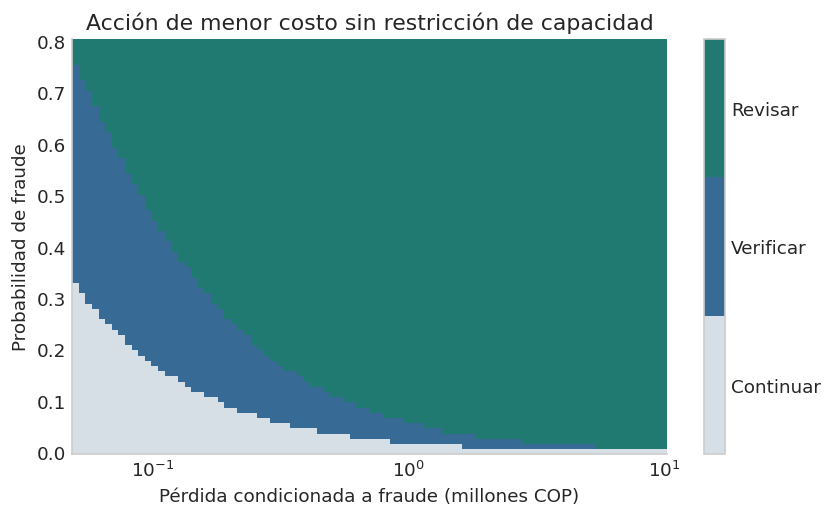

In [2]:
actions=[Action('allow',0,0,0,0),Action('verify',.35,4000,2500,3),Action('review',.8,18000,15000,15)]
loss_grid=np.geomspace(50_000,10_000_000,90)
p_grid=np.linspace(.001,.8,80)
cost_tensor=np.array([[[expected_cost(Case('grid',float(p),float(L)),a) for a in actions] for L in loss_grid] for p in p_grid])
choices=np.argmin(cost_tensor,axis=2)
from matplotlib.colors import ListedColormap
fig,ax=plt.subplots();im=ax.pcolormesh(loss_grid/1e6,p_grid,choices,cmap=ListedColormap(['#D6DFE5',BLUE,TEAL]),vmin=-.5,vmax=2.5,shading='auto')
ax.set(xscale='log',xlabel='Pérdida condicionada a fraude (millones COP)',ylabel='Probabilidad de fraude',title='Acción de menor costo sin restricción de capacidad')
cb=fig.colorbar(im,ax=ax,ticks=[0,1,2]);cb.ax.set_yticklabels(['Continuar','Verificar','Revisar']);plt.show()

El mapa se resuelve sin presupuesto común y solo muestra el efecto de monto y probabilidad. No debe interpretarse como política operativa: al limitar minutos, algunos casos reciben otra acción.

## 2. Elegir acciones conjuntamente


$$\min_{x_{ia}\in\{0,1\}}\sum_{ia}x_{ia}C_i(a),\quad\sum_a x_{ia}=1,\quad\sum_{ia}t_ax_{ia}\leq T.$$

Se compara el mismo conjunto de casos al aumentar capacidad. El conjunto factible crece: el costo óptimo no puede aumentar bajo los mismos supuestos.

,presupuesto_min,usado_min,costo_COP,revisiones,verificaciones
0,0,0.0000,"8,025,285.8963",0,0
1,15,15.0000,"6,321,145.4784",0,5
2,30,30.0000,"5,336,682.3812",1,5
3,60,60.0000,"4,274,124.9431",3,5
4,90,90.0000,"3,659,601.3042",4,10
5,150,150.0000,"2,928,901.8765",9,5


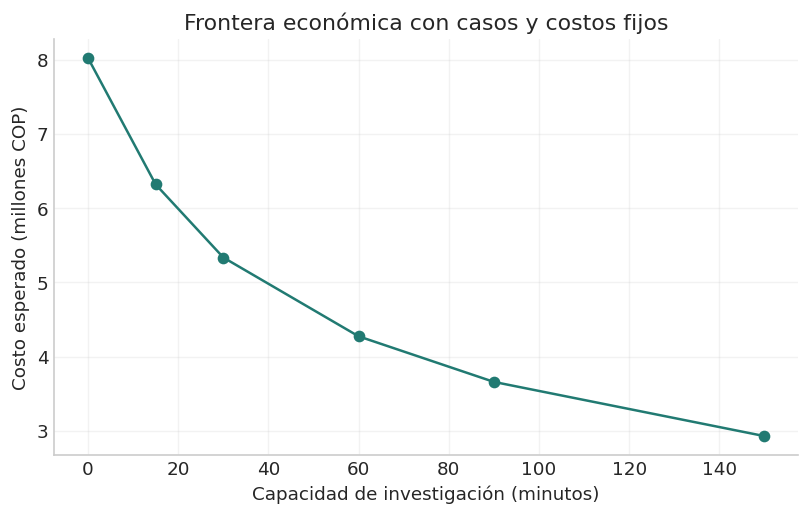

In [3]:
probabilities=rng.beta(1,8,35);losses=rng.lognormal(np.log(1_500_000),.8,35)
cases=[Case(f'synthetic-{i}',float(p),float(L)) for i,(p,L) in enumerate(zip(probabilities,losses))]
capacities=[0,15,30,60,90,150]
plans=[optimize(cases,actions,T) for T in capacities]
capacity_table=pd.DataFrame([{'presupuesto_min':T,'usado_min':p['effort_minutes'],'costo_COP':p['objective_cop'],'revisiones':p['actions'].count('review'),'verificaciones':p['actions'].count('verify')} for T,p in zip(capacities,plans)])
display(capacity_table)
fig,ax=plt.subplots();ax.plot(capacities,capacity_table['costo_COP']/1e6,color=TEAL,marker='o')
ax.set(xlabel='Capacidad de investigación (minutos)',ylabel='Costo esperado (millones COP)',title='Frontera económica con casos y costos fijos');plt.show()

La pendiente depende de casos concretos; no es una estimación del retorno de contratar investigadores. El presupuesto se aplica en minutos y puede quedar sin usar cuando la intervención no tiene beneficio.

## 3. Política congelada ante eficacia incierta


Se conserva el plan elegido con $T=60$ y se reevalúa con $q'_a=\gamma q_a$ acotado a 1. Esto es sensibilidad de supuestos, no recalibración con resultados de prueba.

In [4]:
frozen=plans[3];lookup={a.name:a for a in actions}
no_action=sum(expected_cost(case,actions[0]) for case in cases)
sensitivity=[]
for gamma in [0,.25,.5,.75,1,1.25]:
    scenario=Scenario('efficacy',effectiveness_multiplier=gamma)
    total=sum(expected_cost(case,lookup[a],scenario) for case,a in zip(cases,frozen['actions']))
    sensitivity.append({'gamma':gamma,'costo_COP':total,'beneficio_vs_continuar_COP':no_action-total})
display(pd.DataFrame(sensitivity))

,gamma,costo_COP,beneficio_vs_continuar_COP
0,0.0000,"8,145,292.8359","-120,006.9397"
1,0.2500,"7,177,500.8627","847,785.0335"
2,0.5000,"6,209,708.8895","1,815,577.0067"
3,0.7500,"5,241,916.9163","2,783,368.9800"
4,1.0000,"4,274,124.9431","3,751,160.9532"
5,1.2500,"3,306,332.9699","4,718,952.9264"


Con eficacia cero no hay prevención, pero persisten costos y fricción. Una probabilidad bien estimada no basta: la intervención necesita demostrar utilidad y el supuesto de eficacia debe investigarse.

## Comprobaciones y límites

Las identidades y contraejemplos siguientes son parte del experimento; no verifican desempeño productivo.

In [5]:
assert all(a['objective_cop']>=b['objective_cop']-1e-6 for a,b in zip(plans,plans[1:]))
assert sensitivity[0]['beneficio_vs_continuar_COP'] < 0
assert plans[0]['actions']==['allow']*len(cases)

## Resultados computados

In [6]:
metrics = {'Costo sin capacidad (COP)': round(plans[0]['objective_cop'],2), 'Costo con 60 minutos (COP)': round(plans[3]['objective_cop'],2), 'Costo adicional con eficacia cero (COP)': round(-sensitivity[0]['beneficio_vs_continuar_COP'],2)}
print("LAB_METRICS:" + json.dumps(metrics, ensure_ascii=False))

LAB_METRICS:{"Costo sin capacidad (COP)": 8025285.9, "Costo con 60 minutos (COP)": 4274124.94, "Costo adicional con eficacia cero (COP)": 120006.94}


## Ideas y preguntas para continuar

1. Estimar eficacia por tipo de verificación con un piloto defendible.
2. Añadir tiempo por caso y dos recursos: analista y proveedor.
3. Comparar valor de información de una verificación antes de decidir la revisión.
4. Incorporar demoras y abandono de clientes legítimos como resultados separados.

## Fuentes y relación con el proyecto

- Motor local: `../../loss-minimization-engine/src/engine.py`.
- [SciPy MILP](https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.milp.html).

Consultar también `../README.md` y `../../MODEL_AND_LOSS_METHODS.md`.